In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense 
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

I0000 00:00:1789387202.975703    9840 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
def load_coffee_data():
    rng = np.random.default_rng(2)
    X = rng.random(400).reshape(-1,2)
    X[:,1] = X[:,1] * 4 + 11.5 
    X[:,0] = X[:,0] * (285-150) + 150  
    Y = np.zeros(len(X))
    
    i=0
    for t,d in X:
        y = -3/(260-175)*t + 21
        if (t > 175 and t < 260 and d > 12 and d < 15 and d<=y ):
            Y[i] = 1
        else:
            Y[i] = 0
        i += 1

    return (X, Y.reshape(-1,1))

In [3]:
X,Y = load_coffee_data()
print(X.shape,Y.shape)

(200, 2) (200, 1)


In [4]:
def plt_roast(X,Y):
    Y = Y.reshape(-1,)
    colormap = np.array(['r', 'b'])
    fig, ax = plt.subplots(1,1,)
    ax.scatter(X[Y==1,0],X[Y==1,1], s=70, marker='x', c='red', label="Good Roast" )
    ax.scatter(X[Y==0,0],X[Y==0,1], s=100, marker='o', facecolors='none', 
               edgecolors='blue',linewidth=1,  label="Bad Roast")
    tr = np.linspace(175,260,50)
    ax.plot(tr, (-3/85) * tr + 21, color='purple',linewidth=1)
    ax.axhline(y=12,color='purple',linewidth=1)
    ax.axvline(x=175,color='purple',linewidth=1)
    ax.set_title(f"Coffee Roasting", size=16)
    ax.set_xlabel("Temperature \n(Celsius)",size=12)
    ax.set_ylabel("Duration \n(minutes)",size=12)
    ax.legend(loc='upper right')
    plt.show()

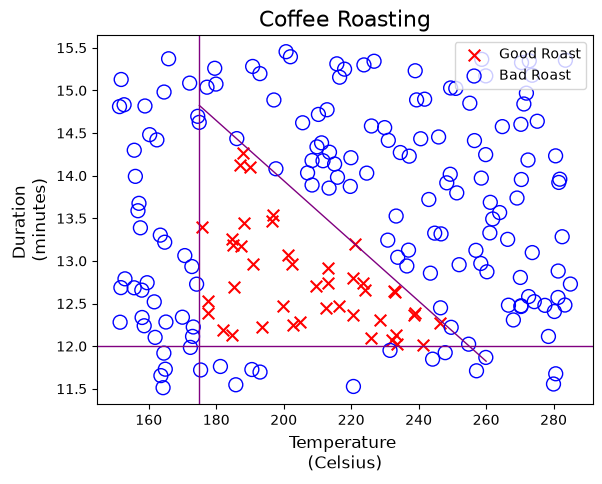

In [5]:
plt_roast(X,Y)

In [6]:
print(f"Temperature Max, Min pre normalization: {np.max(X[:,0]):0.2f}, {np.min(X[:,0]):0.2f}")
print(f"Duration    Max, Min pre normalization: {np.max(X[:,1]):0.2f}, {np.min(X[:,1]):0.2f}")
norm_l = tf.keras.layers.Normalization(axis=-1)
norm_l.adapt(X)
X_norm = norm_l(X)
print(f"Temperature Max, Min after normalization: {np.max(X_norm[:,0]):0.2f}, {np.min(X_norm[:,0]):0.2f}")
print(f"Duration    Max, Min after normalization: {np.max(X_norm[:,1]):0.2f}, {np.min(X_norm[:,1]):0.2f}")

Temperature Max, Min pre normalization: 284.99, 151.32
Duration    Max, Min pre normalization: 15.45, 11.51
Temperature Max, Min after normalization: 1.66, -1.69
Duration    Max, Min after normalization: 1.79, -1.70


In [7]:
X_train = np.tile(X_norm,(1000,1))
Y_train= np.tile(Y,(1000,1))   
print(X_train.shape, Y_train.shape)   

(200000, 2) (200000, 1)


In [8]:
tf.random.set_seed(1234)
model = Sequential(
    [
        tf.keras.Input(shape=(2,)),
        Dense(units=3,activation='sigmoid',name='layer1'),
        Dense(units=1,activation='sigmoid',name='layer2')
    ]
)

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()
print(f"W1{W1.shape}:\n", W1, f"\nb1{b1.shape}:", b1)
print(f"W2{W2.shape}:\n", W2, f"\nb2{b2.shape}:", b2)

W1(2, 3):
 [[ 0.83515453 -0.7177837   0.21865344]
 [ 0.9385412  -0.4789188  -0.5302362 ]] 
b1(3,): [0. 0. 0.]
W2(3, 1):
 [[ 1.1596564]
 [ 0.9853724]
 [-0.8516319]] 
b2(1,): [0.]


In [11]:
W1_init = np.array([[ 0.08, -0.30,  0.18],
                         [-0.56, -0.15,  0.89]])
b1_init = np.array([0., 0., 0.])

W2_init = np.array([[-0.43],
                         [-0.88],
                         [ 0.36]])
b2_init = np.array([0.])

model.get_layer("layer1").set_weights([W1_init, b1_init])
model.get_layer("layer2").set_weights([W2_init, b2_init])

In [12]:
model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01)
)
model.fit(X_train,Y_train,epochs=10)

Epoch 1/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 552us/step - loss: 0.1809
Epoch 2/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 528us/step - loss: 0.1169
Epoch 3/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 539us/step - loss: 0.0451
Epoch 4/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 557us/step - loss: 0.0162
Epoch 5/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 534us/step - loss: 0.0105
Epoch 6/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 550us/step - loss: 0.0073
Epoch 7/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 542us/step - loss: 0.0052
Epoch 8/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 513us/step - loss: 0.0037
Epoch 9/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 490us/step - loss: 0.0027
Epoch 10/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 3s 506us/step - loss: 0.0020


In [13]:
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()
print("W1:\n", W1, "\nb1:", b1)
print("W2:\n", W2, "\nb2:", b2)

W1:
 [[ -0.11612877  14.277117   -11.047227  ]
 [ -8.968328    11.925891    -0.20564725]] 
b1: [-11.194281    1.7960117 -12.071914 ]
W2:
 [[-45.976818]
 [-43.087334]
 [-50.110325]] 
b2: [26.258106]


In [14]:
X_test = np.array([
    [200,13.9],
    [200,17]]) 
X_test_norm = norm_l(X_test)
predictions = model.predict(X_test_norm)
print("Predictions:\n",predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Predictions:
 [[9.767175e-01]
 [4.784638e-08]]


In [15]:
y_hat = np.zeros_like(predictions)
for i in range(len(predictions)):
    if predictions[i]>=0.5:
        y_hat[i]=1
    else:
        y_hat[i]=0
print("Desicions:\n",y_hat)

Desicions:
 [[1.]
 [0.]]


In [16]:
y_hat = (predictions>=0.5).astype(int)
print(f"Desicions:\n{y_hat}")

Desicions:
[[1]
 [0]]
